<a href="https://colab.research.google.com/github/juyeontech00-hue/TIL/blob/main/1_04_cv2_MotionDetection_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 프레임 간 차이(frame differencing)로 모션(움직임) 감지해서
# -> 움직이는 물체 모션 탐지 (물체 주변에 사각형 표시)

In [1]:
import cv2
import time

from google.colab.patches import cv2_imshow
from IPython.display import clear_output


In [ ]:
# 비디오 파일 로드
cap = cv2.VideoCapture('/content/vtest.avi')

## /content/vtest.avi


In [ ]:
# 종료 조건 (원하는 값으로 선택)

timeout_sec = 10          # N초 지나면 종료
max_frames = 500          # N프레임 처리하면 종료
    # 종료 조건으로 둘 중 하나만 사용 가능
show_every = 10           # N프레임마다 화면 출력 (너무 자주 출력하면 느려질 수 있음)

In [ ]:
start_time = time.time()

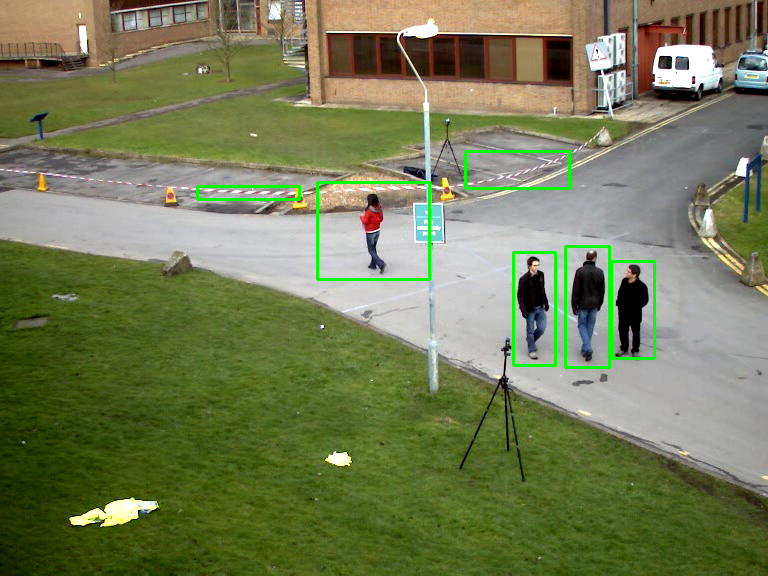

최대 프레임 종료.
 완료. frames=500, elapsed=8.47s


In [ ]:
# 첫 프레임 읽기
ret, frame1 = cap.read()
if not ret:
    print("비디오를 읽을 수 없습니다. 경로/파일을 확인하세요.")
    cap.release()
    raise SystemExit

frame_count = 0

try:
    while True:
        # 시간 제한 종료
        if time.time() - start_time > timeout_sec:
            print("시간 제한 종료.")
            break

        # 최대 프레임 종료
        if frame_count >= max_frames:
            print("최대 프레임 종료.")
            break

        # 다음 프레임 읽기
        ret, frame2 = cap.read()
        if not ret:
            print("비디오 종료(or 프레임 읽기 실패)")
            break

        # 프레임 차이(모션) 계산
        diff = cv2.absdiff(frame1, frame2)

        # 그레이스케일 변환
        gray = cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY)

        # 블러로 노이즈 완화
        blur = cv2.GaussianBlur(gray, (5, 5), 0)

        # 임계값으로 이진화(움직임 영역 강조)
        _, thresh = cv2.threshold(blur, 20, 255, cv2.THRESH_BINARY)

        # 팽창으로 움직임 영역 확장 (뚜렷하게 처리)
        dilated = cv2.dilate(thresh, None, iterations=3)

        # 컨투어 탐색(보통 외곽만 써도 충분)
        contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # 움직임 박스 그리기
        for contour in contours:
            if cv2.contourArea(contour) < 700:
                continue
            x, y, w, h = cv2.boundingRect(contour)
            cv2.rectangle(frame1, (x, y), (x + w, y + h), (0, 255, 0), 2)

        #  N프레임마다 출력 (너무 잦은 출력시 느려질 수 있음)
        if frame_count % show_every == 0:
            clear_output(wait=True)
            cv2_imshow(frame1)

        # 프레임 업데이트
        frame1 = frame2
        frame_count += 1

except KeyboardInterrupt:
    # 런타임에서 중지 버튼 or 인터럽트(Ctrl+M I) 시 중단
    print("KeyboardInterrupt로 중단되었습니다.")

finally:
    cap.release()
    cv2.destroyAllWindows()

elapsed = time.time() - start_time
print(f" 완료. frames={frame_count}, elapsed={elapsed:.2f}s")

In [ ]:
# dilated : 윤곽선을 찾을 이미지
# RETR_EXTERNAL : 바깥쪽 윤곽선만 가져오기
# CHAIN_APPROX_SIMPLE : 윤곽선을 구성하는 점들을 효율적으로 단순화하기
# contours : 탐지한 윤곽선들의 목록
# x	사각형 왼쪽 위의 X좌표
# y	사각형 왼쪽 위의 Y좌표
# w	사각형 너비
# h	사각형 높이
# cap.read()	영상에서 프레임 읽기
# cv2.absdiff()	앞뒤 프레임 차이 계산
# cv2.cvtColor()	차이 이미지를 흑백 변환
# cv2.GaussianBlur()	노이즈 완화
# cv2.threshold()	움직임 후보 영역 이진화
# cv2.dilate()	흰색 영역 확장
# cv2.findContours()	움직임 후보 윤곽선 탐색
# cv2.contourArea()	작은 영역 제외 여부 결정
# cv2.boundingRect()	사각형의 위치와 크기 계산
# cv2.rectangle()	영상에 감지 영역 표시
# frame1 = frame2	다음 프레임 비교를 위해 갱신
# cap.release()	영상 자원 해제